# GE Discovery MI (Listmode Reconstruction; With Time of Flight)

This tutorial demonstrates how to reconstruct data listmode data in HDF5 data obtain from GE scanners. In this tutorial, we'll reconstruct using time-of-flight listmode. The data can be obtained from https://zenodo.org/records/8404015

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/GE-DMI-NEMA")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/GE-DMI-NEMA")
GE_DATA = DATA / 'PET' / 'GE-DMI-NEMA'

PET/GE-DMI-NEMA: already downloaded


In [2]:
import pytomography
from pytomography import io
from pytomography.metadata import ObjectMeta
from pytomography.metadata.PET import PETLMProjMeta
from pytomography.projectors.PET import PETLMSystemMatrix
from pytomography.algorithms import OSEM, BSREM
from pytomography.priors import RelativeDifferencePrior
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.transforms.shared import GaussianFilter
import matplotlib.pyplot as plt

## How much memory this needs

Set `RAM_GB` to the memory this tutorial may use, and pass it to `pytomography.set_memory_budget`: the sensitivity image then goes through GE's 146 million valid crystal pairs in blocks that fit. Each reconstruction prints its estimate before it runs (`estimate_memory`). The tutorial peaks at about 10 GB (measured on Windows), most of it what it holds whatever the budget: the 49 million events with their corrections, the valid pairs with their weights, and PyTorch and CUDA themselves. A lower `RAM_GB` saves little: the tutorial needs about 9 GB however low it is.

In [3]:
RAM_GB = 25 # memory (RAM) this tutorial may use, in GB; it needs about 9 GB however low this is
pytomography.set_memory_budget(RAM_GB)

`io.PET.read_ge_hdf5` reads GE's list mode file: each event's pair of crystals and its time-of-flight bin. The scanner's geometry and TOF bins come from PyTomography's table of clinical scanners: so far only `discovery_MI`, but feel free to make a commit to support other scanners (add to the `src/pytomography/data/pet_scanner_info.txt` file). The list mode has no patient frame, so the grid (`object_meta`, 192 × 192 × 71 voxels of 2.78 mm here) is centred on the scanner's axis, with the bed at the bottom of a transverse slice shown as `image[:, :, k].T`.

In [4]:
folder = GE_DATA / 'dmi_nema_lm'
# The listmode events, the object grid and the projection metadata (the scanner's info and its TOF bins)
detector_ids, object_meta, proj_meta = io.PET.read_ge_hdf5(
    folder / 'LIST0000.BLF',
    object_meta=ObjectMeta(dr=(2.78, 2.78, 2.78), shape=(192, 192, 71)) # mm, voxels
)
info = proj_meta.info

`io.PET.read_ge_corrections` reads GE's corrections for the same events: the multiplicative weight (attenuation and normalization) and the expected scatters and randoms of each event, and every valid pair of crystals with its weight, for the sensitivity image.

In [5]:
weights, additive_counts, detector_ids_sensitivity, weights_sensitivity = io.PET.read_ge_corrections(folder / 'corrections.h5')

First we'll get the required object space and projection space metadata.

* The `object_meta`, from `read_ge_hdf5`, specifies the size of each voxel, the number of voxels in each direction, and where the grid is
* The `proj_meta` specifies the list of all measured listmode events (`detector_ids`), the time-of-flight metadata, and the detector IDs / weights used for computing the sensitivity image.

In [6]:
# The projection metadata: the events, their TOF bins, and every valid crystal pair with its weight
proj_meta = PETLMProjMeta(
    detector_ids,
    info,
    tof_meta=proj_meta.tof_meta,
    detector_ids_sensitivity=detector_ids_sensitivity,
    weights_sensitivity=weights_sensitivity
    )

Now we'll define the system matrix for the PET system. In this case we'll use 4.5mm PSF modeling.

In [7]:
psf_transform = GaussianFilter(4.5) # 4.5mm gaussian psf
system_matrix = PETLMSystemMatrix(
    object_meta,
    proj_meta,
    obj2obj_transforms = [psf_transform],
    N_splits=8,
)

Now we'll define the likelihood function (`PoissonLogLikelihood` for PET systems). The additive term contains scatters/randoms and needs to be normalized by the `weights`.

In [8]:
likelihood = PoissonLogLikelihood(
    system_matrix,
    additive_term=additive_counts/weights,
)

We can now reconstruct using a variety of reconstruction algorithms:

In [9]:
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=34)) # its peak RAM and GPU memory, before it runs
recon_OSEM = recon_algorithm(n_iters=2, n_subsets=34)

OSEM (PETLMSystemMatrix): 34 subsets, memory budget 25 GB
Peak ~ 9.9 GB RAM, 3.0 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.8 GB RAM, 1.4 GB GPU (events and their projector order 0.8 GPU, sensitivity weights 0.6 RAM, detector IDs of the sensitivity weights 1.2 RAM, sensitivity and normalisation images (34) 0.4 GPU, image, update and attenuation map 0.04 GPU, projections (the data) 0.00 GPU, additive term 0.2 GPU)
  one subset at a time: 0.00 GB RAM, 0.3 GB GPU (expected counts, ratio and temporaries (one subset) 0.02 GPU, positions of the subset's events 0.01 GPU, building a subset's projector order (its first projection) 0.3 GPU)
  projector chunks: 0.00 GB RAM, 0.01 GB GPU (projector chunk 0.01 GPU)
  Python, CUDA, allocator: 5.1 GB RAM, 1.3 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.6 GPU, memory the allocators keep (Windows) 2.1 RAM)
To 

In [10]:
# This is probably very similar to "Q.Clear" is ;)
prior = RelativeDifferencePrior(beta=25, gamma=2)
recon_algorithm = BSREM(likelihood, prior=prior)
print(recon_algorithm.estimate_memory(n_subsets=34))
recon_BSREM = recon_algorithm(n_iters=20, n_subsets=34)

BSREM (PETLMSystemMatrix): 34 subsets, memory budget 25 GB
Peak ~ 10.8 GB RAM, 3.6 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.8 GB RAM, 1.4 GB GPU (events and their projector order 0.8 GPU, sensitivity weights 0.6 RAM, detector IDs of the sensitivity weights 1.2 RAM, sensitivity and normalisation images (34) 0.4 GPU, image, update and attenuation map 0.04 GPU, projections (the data) 0.00 GPU, additive term 0.2 GPU, prior: its copy of the image, field of view scale and gradient 0.03 GPU)
  one subset at a time: 0.00 GB RAM, 0.7 GB GPU (expected counts, ratio and temporaries (one subset) 0.02 GPU, positions of the subset's events 0.01 GPU, building a subset's projector order (its first projection) 0.3 GPU, prior: temporaries of its gradient 0.1 GPU, H_m^T 1 of the 34 subsets stacked, and their sum 0.4 GPU)
  projector chunks: 0.00 GB RAM, 0.01 GB GPU (projector chunk 0.01 GPU)
  Python, CUDA, allocator: 5.4 GB RAM, 1.5 GB GPU (Python, PyTorch and CUDA 3

Plot a transverse slice through the spheres of each reconstruction, with the bed at the bottom:

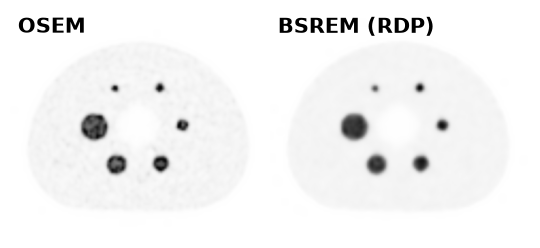

In [11]:
fig, ax = plt.subplots(1,2,figsize=(5.5,3), gridspec_kw={'wspace': 0.0})   
plt.subplot(121)
plt.imshow(recon_OSEM[:,:,20].T.cpu(), cmap='Greys', interpolation='gaussian', vmax=0.5)
plt.axis('off')
plt.text(0.03, 0.97, 'OSEM', color='black', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')
plt.xlim(34,156)
plt.ylim(146,39)
plt.subplot(122)
plt.imshow(recon_BSREM[:,:,20].T.cpu(), cmap='Greys', interpolation='gaussian', vmax=0.5)
plt.axis('off')
plt.text(0.03, 0.97, 'BSREM (RDP)', color='black', fontsize=15, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')
plt.xlim(34,156)
plt.ylim(146,39)
fig.tight_layout()
plt.show()

## Save the images

`io.save_dicom` writes both reconstructions as DICOM PET series, one file per slice, where `object_meta` places them. The list-mode files carry no patient frame, so the images are centred on the scanner's axis, where PyTomography reconstructs them.

In [12]:
for name, image in [('osem', recon_OSEM), ('bsrem', recon_BSREM)]:
    io.save_dicom(image, OUTPUT / 't_GE_HDF5' / name, object_meta, series_description=name.upper(), overwrite=True)

In [13]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 1.8, "peak_ram_gb": 9.3}
